
# **Tri-State Accident Data Analysis**


    


## **Abstract**

The goal of this project is to create a comprehensive, standardized traffic accident dataset spanning Pennsylvania, New York, and Delaware by integrating data from state-level Departments of Transportation. We will collect data through both API endpoints and archived files from state transportation departments, implementing data cleaning and normalization processes to ensure consistency across different state reporting formats. Key challenges include standardizing various data representations, resolving geographic location discrepancies, and establishing uniform categorical classifications across state lines.

The resulting dataset will serve multiple stakeholders, including:
- Government agencies for infrastructure planning and policy development
- Researchers studying regional traffic safety patterns
- Emergency response planners optimizing resource allocation
- Insurance companies conducting risk assessments

The dataset will be publicly accessible through Kaggle,  accompanied by comprehensive documentation. This work represents a step toward improving traffic safety analysis and infrastructure planning in the northeastern United States through enhanced data accessibility and standardization.




    

We plan to combine government-provided traffic accident data from three states in the region: Pennsylvania, New York, and Delaware.

### **Motivation and Relevance**

The combined dataset will provide actionable insights to government officials as well as private individuals. Government agencies can use this data to inform infrastructure planning, and improve the safety of interstate commuting. Individuals can benefit by basing relocation decisions (at least partially) on traffic safety along the route of their commute.
    


## **Data Collection**

### **Sources**

Our data set will combine accident data from three official sources:
- [pennshare.maps.arcgis.com](https://pennshare.maps.arcgis.com/apps/webappviewer/index.html?id=8fdbf046e36e41649bbfd9d7dd7c7e7e)
- [data.ny.gov](https://data.ny.gov/Transportation/Motor-Vehicle-Crashes-Case-Information-Three-Year-/e8ky-4vqe/explore/query/SELECT%0A%20%20%60year%60%2C%0A%20%20%60accident_descriptor%60%2C%0A%20%20%60time%60%2C%0A%20%20%60date%60%2C%0A%20%20%60day_of_week%60%2C%0A%20%20%60police_report%60%2C%0A%20%20%60lighting_conditions%60%2C%0A%20%20%60municipality%60%2C%0A%20%20%60collision_type_descriptor%60%2C%0A%20%20%60county_name%60%2C%0A%20%20%60road_descriptor%60%2C%0A%20%20%60weather_conditions%60%2C%0A%20%20%60traffic_control_device%60%2C%0A%20%20%60road_surface_conditions%60%2C%0A%20%20%60dot_reference_marker_location%60%2C%0A%20%20%60pedestrian_bicyclist_action%60%2C%0A%20%20%60event_descriptor%60%2C%0A%20%20%60number_of_vehicles_involved%60/page/filter)
- [data.delaware.gov](https://data.delaware.gov/Transportation/Public-Crash-Data/827n-m6xc/explore/query/SELECT%0A%20%20%60crash_datetime%60%2C%0A%20%20%60day_of_week%60%2C%0A%20%20%60day_of_week_desc%60%2C%0A%20%20%60crash_class%60%2C%0A%20%20%60crash_class_desc%60%2C%0A%20%20%60priv_prop_coll%60%2C%0A%20%20%60ped_involved%60%2C%0A%20%20%60impact%60%2C%0A%20%20%60impact_desc%60%2C%0A%20%20%60alcohol_involved%60%2C%0A%20%20%60drug_involved%60%2C%0A%20%20%60road_surface%60%2C%0A%20%20%60road_surface_desc%60%2C%0A%20%20%60light_cond%60%2C%0A%20%20%60light_cond_desc%60%2C%0A%20%20%60weather_1%60%2C%0A%20%20%60weather_1_desc%60%2C%0A%20%20%60weather_2%60%2C%0A%20%20%60weather_2_desc%60%2C%0A%20%20%60seatbelt_used%60%2C%0A%20%20%60mc_involved%60%2C%0A%20%20%60mc_helmet_used%60%2C%0A%20%20%60bike_involved%60%2C%0A%20%20%60bike_helmet_used%60%2C%0A%20%20%60latitude%60%2C%0A%20%20%60longitude%60%2C%0A%20%20%60pri_contrib_circum%60%2C%0A%20%20%60pri_contrib_circum_desc%60%2C%0A%20%20%60school_bus_involved%60%2C%0A%20%20%60school_bus_involved_desc%60%2C%0A%20%20%60work_zone%60%2C%0A%20%20%60work_zone_location%60%2C%0A%20%20%60work_zone_location_desc%60%2C%0A%20%20%60work_zone_type%60%2C%0A%20%20%60work_zone_type_desc%60%2C%0A%20%20%60workers_present%60%2C%0A%20%20%60the_geom%60%2C%0A%20%20%60county%60%2C%0A%20%20%60county_desc%60/page/filter)

All datasets contain location information such as latitude, longitude, and municipality, as well as accident details, road and weather conditions, etc.

### **Data Availability and Feasibility**

All data sets are available to the public in tabular format (xls, csv). The NY and DE data are also accessible via queryable APIs.


### **Dataset Creation**

This data is created through real world car crashes that is tracked at the state level by the Department of Transportation, collected primarily through crash reports from law enforcement. Each record represents one crash.


### **Dataset Limitations**

While the PA and DE datasets include specific location (coordinates), the NY data does not. This will limit the granularity of our combined dataset. We will need to convert all coordinate locations to municipalities (e.g using the [geoapify.com reverse geocoding API](https://www.geoapify.com/reverse-geocoding-api/)).

Additionally, PA data is only available as a `.zip` archive—not via API—which complicates data collection slightly. PA data will need to be pre-loaded in bulk whereas NY and DE data can be retrieved on demand.
    

In [ ]:
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen
import os
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



file_cache_path = '/tmp/DSCI-511/data_cache'

if not os.path.exists(file_cache_path):
    os.makedirs(file_cache_path)


def hash_dictionary(dictionary):
    return hashlib.sha256(json.dumps(dictionary, sort_keys=True).encode()).hexdigest()


def disk_cached(function):
    def wrapper(*args, **kwargs):
        arg_hash  = hash_dictionary({
            'args': args,
            'kwargs': kwargs,
        })

        data = None
        file_path = os.path.join(file_cache_path, f"{function.__name__}.{arg_hash}.csv")

        if not os.path.exists(file_path):
            data = function(*args, **kwargs)
            data.to_csv(file_path, sep=',') # Expected to be a pandas DataFrame

        return data if data is not None else pd.read_csv(file_path)

    return wrapper



In [ ]:
'''
Fetch PA data
'''

@disk_cached
def fetch_pa_data_for_year(year):
    if not (2004 <= year < 2024):
        raise Exception(f'Data is not available for {str(year)}')

    response = urlopen(f'https://gis.penndot.gov/gishub/crashZip/Statewide/Statewide_{str(year)}.zip')
    archive = ZipFile(BytesIO(response.read()))

    with archive.open(f'CRASH_{year}.csv') as file:
        return pd.read_csv(file)

# Note: archives are large and will take several seconds to download the first time this runs
data = fetch_pa_data_for_year(2020)
data.head()

,CRN,ARRIVAL_TM,AUTOMOBILE_COUNT,BELTED_DEATH_COUNT,BELTED_SUSP_SERIOUS_INJ_COUNT,BICYCLE_COUNT,BICYCLE_DEATH_COUNT,BICYCLE_SUSP_SERIOUS_INJ_COUNT,BUS_COUNT,CHLDPAS_DEATH_COUNT,...,WORK_ZONE_TYPE,WORKERS_PRES,WZ_CLOSE_DETOUR,WZ_FLAGGER,WZ_LAW_OFFCR_IND,WZ_LN_CLOSURE,WZ_MOVING,WZ_OTHER,WZ_SHLDER_MDN,WZ_WORKERS_INJ_KILLED
0,2020029555,1053.0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2020029195,944.0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2020003748,832.0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2020022125,808.0,2,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2020007424,1046.0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import requests
import urllib.parse
import datetime

def fetch_data_from_socrata_api(base_url,year,columns,date_column='date'):
    accumumulator = []

    while True:
        select_clause = '$select=' + ','.join(columns)

        begin_date_iso = datetime.datetime(year, 1, 1).strftime('%Y-%m-%d')
        end_date_iso = datetime.datetime(year + 1, 1, 1).strftime('%Y-%m-%d')
        where_clause = f'$where=date between \'{begin_date_iso}\' and \'{end_date_iso}\''


        select_clause = 'SELECT ' + ',\n'.join(f'`{column}`' for column in columns)
        where_clause = f'WHERE {date_column} >= \'{begin_date_iso}\' AND {date_column} <= \'{end_date_iso}\''

        limit_clause = 'LIMIT 25000'

        offset = len(accumumulator)
        offset_clause = f'OFFSET {offset}'


        query = f'{select_clause}\n{where_clause}\n{limit_clause}\n{offset_clause}'

        queryString = urllib.parse.quote(query, safe='')
        url = f'{base_url}?$query={queryString}'
        response = requests.get(url)
        data = response.json()

        if len(data) == 0:
            return pd.DataFrame(accumumulator)
        else:
            accumumulator.extend(data)
            print(f'Fetched {len(data)} records from {base_url} (total {len(accumumulator)})')



In [ ]:
'''
Fetch NY data
'''

NY_COLUMNS = [
    'year',
    'accident_descriptor',
    'time',
    'date',
    'day_of_week',
    'police_report',
    'lighting_conditions',
    'municipality',
    'collision_type_descriptor',
    'county_name',
    'road_descriptor',
    'weather_conditions',
    'traffic_control_device',
    'road_surface_conditions',
    'dot_reference_marker_location',
    'pedestrian_bicyclist_action',
    'event_descriptor',
    'number_of_vehicles_involved',
]


@disk_cached
def fetch_ny_data_for_year(year, columns=NY_COLUMNS):

    return fetch_data_from_socrata_api(
        'https://data.ny.gov/resource/e8ky-4vqe.json',
        year,
        columns,
    )


data = fetch_ny_data_for_year(2020)
data.head()

Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 25000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 50000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 75000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 100000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 125000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 150000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 175000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 200000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 225000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 250000)
Fetched 25000 records from https://data.ny.gov/resource/e8ky-4vqe.json (total 275000)
Fetched 25000 records from https://data.ny.gov/resource/e

,year,accident_descriptor,time,date,day_of_week,police_report,lighting_conditions,municipality,collision_type_descriptor,county_name,road_descriptor,weather_conditions,traffic_control_device,road_surface_conditions,dot_reference_marker_location,pedestrian_bicyclist_action,event_descriptor,number_of_vehicles_involved
0,2020,Property Damage & Injury Accident,18:31,2020-01-01T00:00:00.000,Wednesday,Y,Dark-Road Lighted,WEST SENECA,LEFT TURN (3),ERIE,Straight and Level,Cloudy,Traffic Signal,Dry,240 53011278,Not Applicable,"Other Motor Vehicle, Collision With",2
1,2020,Property Damage Accident,1:38,2020-01-01T00:00:00.000,Wednesday,Y,Dark-Road Lighted,HAMBURG,REAR END,ERIE,Straight and Level,Cloudy,Traffic Signal,Snow/Ice,20 53021207,Not Applicable,"Other Motor Vehicle, Collision With",2
2,2020,Fatal Accident,17:51,2020-01-01T00:00:00.000,Wednesday,Y,Daylight,QUEENS,OTHER,QUEENS,Straight and Level,Clear,None,Dry,NaN,Unknown,"Pedestrian, Collision With",1
3,2020,Property Damage Accident,19:35,2020-01-01T00:00:00.000,Wednesday,Y,Dark-Road Lighted,LIVONIA,OTHER,LIVINGSTON,Straight and Grade,Cloudy,None,Snow/Ice,15 42021205,Not Applicable,Deer,1
4,2020,Property Damage Accident,3:12,2020-01-01T00:00:00.000,Wednesday,Y,Dark-Road Unlighted,HOPEWELL,OTHER,ONTARIO,Straight and Level,Cloudy,No Passing Zone,Dry,21 44053019,Not Applicable,Deer,1


In [ ]:
'''
Fetch DE data
'''

DE_COLUMNS = [
    'crash_datetime',
    'day_of_week',
    'day_of_week_desc',
    'crash_class',
    'crash_class_desc',
    'priv_prop_coll',
    'ped_involved',
    'impact',
    'impact_desc',
    'alcohol_involved',
    'drug_involved',
    'road_surface',
    'road_surface_desc',
    'light_cond',
    'light_cond_desc',
    'weather_1',
    'weather_1_desc',
    'weather_2',
    'weather_2_desc',
    'seatbelt_used',
    'mc_involved',
    'mc_helmet_used',
    'bike_involved',
    'bike_helmet_used',
    'latitude',
    'longitude',
    'pri_contrib_circum',
    'pri_contrib_circum_desc',
    'school_bus_involved',
    'school_bus_involved_desc',
    'work_zone',
    'work_zone_location',
    'work_zone_location_desc',
    'work_zone_type',
    'work_zone_type_desc',
    'workers_present',
    'the_geom',
    'county',
    'county_desc',
]


@disk_cached
def fetch_de_data_for_year(year, columns=DE_COLUMNS):

    return fetch_data_from_socrata_api(
        'https://data.delaware.gov/resource/827n-m6xc.json',
        year,
        columns,
        date_column='crash_datetime',
    )

data = fetch_de_data_for_year(2020)
data.head()

Fetched 25000 records from https://data.delaware.gov/resource/827n-m6xc.json (total 25000)
Fetched 6664 records from https://data.delaware.gov/resource/827n-m6xc.json (total 31664)


,crash_datetime,day_of_week,day_of_week_desc,crash_class,crash_class_desc,priv_prop_coll,ped_involved,impact,impact_desc,alcohol_involved,...,school_bus_involved_desc,work_zone,work_zone_location,work_zone_location_desc,work_zone_type,work_zone_type_desc,workers_present,the_geom,county,county_desc
0,2020-01-01T00:37:00.000Z,3,Tuesday,03,Personal Injury Crash,N,N,00,Not a collision between two vehicles,N,...,No,N,NA,NA,NA,NA,N,"{'type': 'Point', 'coordinates': [-75.42526999...",S,Sussex
1,2020-01-01T00:50:00.000Z,3,Tuesday,02,Property Damage Only,N,N,04,"Sideswipe, same direction",N,...,No,N,NA,NA,NA,NA,N,"{'type': 'Point', 'coordinates': [-75.70314999...",N,New Castle
2,2020-01-01T00:57:00.000Z,3,Tuesday,02,Property Damage Only,N,N,01,Front to rear,N,...,No,N,NA,NA,NA,NA,N,"{'type': 'Point', 'coordinates': [-75.71341999...",N,New Castle
3,2020-01-01T00:58:00.000Z,3,Tuesday,02,Property Damage Only,N,N,00,Not a collision between two vehicles,N,...,No,N,NA,NA,NA,NA,N,"{'type': 'Point', 'coordinates': [-75.72850999...",N,New Castle
4,2020-01-01T01:08:00.000Z,3,Tuesday,02,Property Damage Only,N,N,00,Not a collision between two vehicles,N,...,No,N,NA,NA,NA,NA,N,"{'type': 'Point', 'coordinates': [-75.59431000...",N,New Castle



## **Data Construction**

The goal in our construction is to determine where there is overlap in all three datsets and standardize the datasets, so that we have one cohesive dataset. This consists of making datatypes consistent, manipulating data and column names and combining data.

In [ ]:
%%capture
'''
Get Data for each state using functions.
'''

pa_data = pd.DataFrame()
de_data = pd.DataFrame()
ny_data = pd.DataFrame()

for year in range(2018,2024):
  # get data for year
  pa_df = fetch_pa_data_for_year(year);
  de_df = fetch_de_data_for_year(year);
  ny_df = fetch_ny_data_for_year(year);

  # concat to df for state
  pa_data = pd.concat([pa_data, pa_df], axis=0)
  de_data = pd.concat([de_data, de_df], axis=0)
  ny_data = pd.concat([ny_data, ny_df], axis=0)


In [ ]:
pa_data.columns.to_list()

['CRN',
 'ARRIVAL_TM',
 'AUTOMOBILE_COUNT',
 'BELTED_DEATH_COUNT',
 'BELTED_SUSP_SERIOUS_INJ_COUNT',
 'BICYCLE_COUNT',
 'BICYCLE_DEATH_COUNT',
 'BICYCLE_SUSP_SERIOUS_INJ_COUNT',
 'BUS_COUNT',
 'CHLDPAS_DEATH_COUNT',
 'CHLDPAS_SUSP_SERIOUS_INJ_COUNT',
 'COLLISION_TYPE',
 'COMM_VEH_COUNT',
 'CONS_ZONE_SPD_LIM',
 'COUNTY',
 'CRASH_MONTH',
 'CRASH_YEAR',
 'DAY_OF_WEEK',
 'DEC_LAT',
 'DEC_LONG',
 'DISPATCH_TM',
 'DISTRICT',
 'DRIVER_COUNT_16YR',
 'DRIVER_COUNT_17YR',
 'DRIVER_COUNT_18YR',
 'DRIVER_COUNT_19YR',
 'DRIVER_COUNT_20YR',
 'DRIVER_COUNT_50_64YR',
 'DRIVER_COUNT_65_74YR',
 'DRIVER_COUNT_75PLUS',
 'EST_HRS_CLOSED',
 'FATAL_COUNT',
 'HEAVY_TRUCK_COUNT',
 'HORSE_BUGGY_COUNT',
 'HOUR_OF_DAY',
 'ILLUMINATION',
 'INJURY_COUNT',
 'INTERSECT_TYPE',
 'INTERSECTION_RELATED',
 'LANE_CLOSED',
 'LATITUDE',
 'LN_CLOSE_DIR',
 'LOCATION_TYPE',
 'LONGITUDE',
 'MAX_SEVERITY_LEVEL',
 'MCYCLE_DEATH_COUNT',
 'MCYCLE_SUSP_SERIOUS_INJ_COUNT',
 'MOTORCYCLE_COUNT',
 'MUNICIPALITY',
 'NONMOTR_COUNT',
 'NONM

In [ ]:
de_data.columns.to_list()

['crash_datetime',
 'day_of_week',
 'day_of_week_desc',
 'crash_class',
 'crash_class_desc',
 'priv_prop_coll',
 'ped_involved',
 'impact',
 'impact_desc',
 'alcohol_involved',
 'drug_involved',
 'road_surface',
 'road_surface_desc',
 'light_cond',
 'light_cond_desc',
 'weather_1',
 'weather_1_desc',
 'weather_2',
 'weather_2_desc',
 'seatbelt_used',
 'mc_involved',
 'mc_helmet_used',
 'bike_involved',
 'bike_helmet_used',
 'latitude',
 'longitude',
 'pri_contrib_circum',
 'pri_contrib_circum_desc',
 'school_bus_involved',
 'school_bus_involved_desc',
 'work_zone',
 'work_zone_location',
 'work_zone_location_desc',
 'work_zone_type',
 'work_zone_type_desc',
 'workers_present',
 'the_geom',
 'county',
 'county_desc',
 'Unnamed: 0']

In [ ]:
ny_data.columns.to_list()

['year',
 'accident_descriptor',
 'time',
 'date',
 'day_of_week',
 'police_report',
 'lighting_conditions',
 'municipality',
 'collision_type_descriptor',
 'county_name',
 'road_descriptor',
 'weather_conditions',
 'traffic_control_device',
 'road_surface_conditions',
 'pedestrian_bicyclist_action',
 'event_descriptor',
 'number_of_vehicles_involved',
 'dot_reference_marker_location',
 'Unnamed: 0']

Overlapping information includes:


*   time
*   month
*   year
*   day of the week
*   fields describing nature of accident i.e. fatal crash, fender bender, etc.
*   location - county
*   whether it was a multi-vehicle crash (T/F) can be derived
*   pedestrian(s) involved (T/F) can be derived
*   whether it was a fatal crash (T/F) can be derived
*   road conditions
*   lighting conditions
*   weather conditions



In [ ]:
### copy data before cleaning
pa_data_clean = pa_data.copy()
de_data_clean = de_data.copy()
ny_data_clean = ny_data.copy()

In [ ]:
### add state column
pa_data_clean['state'] = 'PA'
de_data_clean['state'] = 'DE'
ny_data_clean['state'] = 'NY'

In [ ]:
### CLEAN PA DATA ###

# map data to standard terms
day_mapping = {
    1: 'Sunday',
    2: 'Monday',
    3: 'Tuesday',
    4: 'Wednesday',
    5: 'Thursday',
    6: 'Friday',
    7: 'Saturday',
    9: None
}

collision_mapping = {
    0: 'Non-collision',
    1: 'Rear-end',
    2: 'Head-on',
    3: 'Backing',
    4: 'Angle',
    5: 'Sideswipe (same dir.)',
    6: 'Sideswipe (Opposite dir.)',
    7: 'Hit Fixed Object',
    8: 'Hit Non-Motorist',
    9: 'Other/Unknown (Expired)',
    98: 'Other',
    99: None
}

severity_mapping = {
    0: 'Property Damage Only',
    1: 'Fatal',
    2: 'Suspected Serious Injury',
    3: 'Suspected Minor Injury',
    4: 'Possible Injury',
    8: 'Injury – Unknown Severity',
    9: 'Unknown if Injured'
}

county_mapping = {
    1: 'ADAMS',
    2: 'ALLEGHENY',
    3: 'ARMSTRONG',
    4: 'BEAVER',
    5: 'BEDFORD',
    6: 'BERKS',
    7: 'BLAIR',
    8: 'BRADFORD',
    9: 'BUCKS',
    10: 'BUTLER',
    11: 'CAMBRIA',
    12: 'CAMERON',
    13: 'CARBON',
    14: 'CENTRE',
    15: 'CHESTER',
    16: 'CLARION',
    17: 'CLEARFIELD',
    18: 'CLINTON',
    19: 'COLUMBIA',
    20: 'CRAWFORD',
    21: 'CUMBERLAND',
    22: 'DAUPHIN',
    23: 'DELAWARE',
    24: 'ELK',
    25: 'ERIE',
    26: 'FAYETTE',
    27: 'FOREST',
    28: 'FRANKLIN',
    29: 'FULTON',
    30: 'GREENE',
    31: 'HUNTINGDON',
    32: 'INDIANA',
    33: 'JEFFERSON',
    34: 'JUNIATA',
    35: 'LACKAWANNA',
    36: 'LANCASTER',
    37: 'LAWRENCE',
    38: 'LEBANON',
    39: 'LEHIGH',
    40: 'LUZERNE',
    41: 'LYCOMING',
    42: 'MCKEAN',
    43: 'MERCER',
    44: 'MIFFLIN',
    45: 'MONROE',
    46: 'MONTGOMERY',
    47: 'MONTOUR',
    48: 'NORTHAMPTON',
    49: 'NORTHUMBERLAND',
    50: 'PERRY',
    51: 'PIKE',
    52: 'POTTER',
    53: 'SCHUYLKILL',
    54: 'SNYDER',
    55: 'SOMERSET',
    56: 'SULLIVAN',
    57: 'SUSQUEHANNA',
    58: 'TIOGA',
    59: 'UNION',
    60: 'VENANGO',
    61: 'WARREN',
    62: 'WASHINGTON',
    63: 'WAYNE',
    64: 'WESTMORELAND',
    65: 'WYOMING',
    66: 'YORK',
    67: 'PHILADELPHIA'
}

lighting_mapping = {
    1: 'Daylight',
    2: 'Dark – no streetlights',
    3: 'Dark – streetlights',
    4: 'Dusk',
    5: 'Dawn',
    6: 'Dark – unknown roadway lighting',
    8: 'Other',
    9: None
}

road_cond_mapping = {
    1: 'Dry',
    2: 'Ice/Frost',
    3: 'Mud, Dirt, Gravel',
    4: 'Oil',
    5: 'Sand',
    6: 'Slush',
    7: 'Snow',
    8: 'Water (Standing or Moving)',
    9: 'Wet',
    22: 'Mud, Sand, Dirt, Oil (Expired 1-1-20)',
    98: 'Other',
    99: None
}

weather_mapping = {
    1: 'Blowing Sand, Soil, Dirt',
    2: 'Blowing Snow',
    3: 'Clear',
    4: 'Cloudy',
    5: 'Fog, Smog, Smoke',
    6: 'Freezing Rain or Freezing Drizzle',
    7: 'Rain',
    8: 'Severe Crosswinds',
    9: 'Sleet or Hail',
    10: 'Snow',
    98: 'Other',
    99: None
}

In [ ]:
# relevent columns
# pa data is missing date column, waiting to see if this can be fixed
pa_data_clean = pa_data_clean[['CRASH_MONTH','CRASH_YEAR','DAY_OF_WEEK','TIME_OF_DAY','FATAL_COUNT','COLLISION_TYPE','MAX_SEVERITY_LEVEL','COUNTY','state','ILLUMINATION','ROAD_CONDITION','WEATHER1','PED_COUNT','VEHICLE_COUNT']]

# convert floats to ints
pa_data_clean['TIME_OF_DAY'] = pd.to_numeric(pa_data_clean['TIME_OF_DAY'], errors='coerce').astype('Int64')
pa_data_clean['WEATHER1'] = pd.to_numeric(pa_data_clean['WEATHER1'], errors='coerce').astype('Int64')

# apply mappings
pa_data_clean['day_of_week'] = pa_data_clean['DAY_OF_WEEK'].map(day_mapping)
pa_data_clean['collision_type'] = pa_data_clean['COLLISION_TYPE'].map(collision_mapping)
pa_data_clean['crash_class'] = pa_data_clean['MAX_SEVERITY_LEVEL'].map(severity_mapping)
pa_data_clean['county'] = pa_data_clean['COUNTY'].map(county_mapping)
pa_data_clean['lighting_conditions'] = pa_data_clean['ILLUMINATION'].map(lighting_mapping)
pa_data_clean['road_conditions'] = pa_data_clean['ROAD_CONDITION'].map(road_cond_mapping)
pa_data_clean['weather_conditions'] = pa_data_clean['WEATHER1'].map(weather_mapping)

# convert time
pa_data_clean['time'] = pa_data_clean['TIME_OF_DAY'].apply(lambda x: datetime.time(int(x // 100), int(x % 100)) if (x < 2400) and (x.is_integer()) else None)
pa_data_clean['year'] = pa_data_clean['CRASH_YEAR'].astype(int, errors='ignore')
pa_data_clean['month'] = pa_data_clean['CRASH_MONTH'].astype(int, errors='ignore')

# interpret bool columns
pa_data_clean['fatal'] = pa_data_clean['FATAL_COUNT'].apply(lambda x: True if x > 0 else False)
pa_data_clean['pedestrian_involved'] = pa_data_clean['PED_COUNT'].apply(lambda x: True if x > 0 else False)
pa_data_clean['multi_vehicle'] = pa_data_clean['VEHICLE_COUNT'].apply(lambda x: True if x > 1 else False)

# new columns
pa_data_clean = pa_data_clean[['year','month','day_of_week','time','county','state','collision_type','crash_class','fatal','pedestrian_involved','multi_vehicle','lighting_conditions','road_conditions','weather_conditions']]

# convert data types
pa_data_clean.head()

,year,month,day_of_week,time,county,state,collision_type,crash_class,fatal,pedestrian_involved,multi_vehicle,lighting_conditions,road_conditions,weather_conditions
0,2018,3,Thursday,10:43:00,ADAMS,PA,Rear-end,Property Damage Only,False,False,True,Daylight,Wet,Rain
1,2018,1,Tuesday,15:32:00,ADAMS,PA,Rear-end,Property Damage Only,False,False,True,Daylight,Dry,Clear
2,2018,1,Tuesday,10:47:00,ADAMS,PA,Angle,Possible Injury,False,False,True,Daylight,Dry,Clear
3,2018,1,Thursday,05:30:00,ADAMS,PA,Hit Fixed Object,Injury – Unknown Severity,False,False,False,Dark – streetlights,Snow,Snow
4,2018,3,Wednesday,09:37:00,ADAMS,PA,Angle,Injury – Unknown Severity,False,False,True,Daylight,Wet,Rain


In [ ]:
### CLEAN DE DATA ###

# get relevant columns
de_data_clean = de_data_clean[['crash_datetime','day_of_week_desc','crash_class_desc','ped_involved','impact_desc','road_surface_desc','light_cond_desc','weather_1_desc','county_desc','state']]

# date time columns
de_data_clean['month'] = pd.to_datetime(de_data_clean['crash_datetime']).dt.month
de_data_clean['year'] = pd.to_datetime(de_data_clean['crash_datetime']).dt.year
de_data_clean['time'] = pd.to_datetime(de_data_clean['crash_datetime']).dt.time

# rename columns
de_data_clean = de_data_clean.rename(columns={
    'day_of_week_desc':'day_of_week',
    'crash_class_desc':'crash_class',
    'impact_desc':'collision_type',
    'road_surface_desc':'road_conditions',
    'light_cond_desc':'lighting_conditions',
    'weather_1_desc':'weather_conditions',
    'county_desc':'county'})

# interpret bool columns
de_data_clean['fatal'] = de_data_clean['crash_class'].apply(lambda x: True if x == 'Fatality Crash' else False)
de_data_clean['pedestrian_involved'] = de_data_clean['ped_involved'].apply(lambda x: True if x == 'Y' else False)
de_data_clean['multi_vehicle'] = de_data_clean['collision_type'].apply(lambda x: True if x != 'Not a collision between two vehicles' else False)

# get relevant columns
de_data_clean = de_data_clean[['year','month','day_of_week','time','county','state','collision_type','crash_class','fatal','pedestrian_involved','multi_vehicle','lighting_conditions','road_conditions','weather_conditions']]

de_data_clean.head()


,year,month,day_of_week,time,county,state,collision_type,crash_class,fatal,pedestrian_involved,multi_vehicle,lighting_conditions,road_conditions,weather_conditions
0,2018,1,Sunday,00:24:00,New Castle,DE,Not a collision between two vehicles,Property Damage Only,False,False,False,Dark-Not Lighted,Dry,Clear
1,2018,1,Sunday,00:55:00,New Castle,DE,Rear to rear,Property Damage Only,False,False,True,Dark-Lighted,Dry,Cloudy
2,2018,1,Sunday,01:00:00,New Castle,DE,Unknown,Property Damage Only,False,False,True,Unknown,Unknown,Unknown
3,2018,1,Sunday,01:13:00,New Castle,DE,Angle,Property Damage Only,False,False,True,Dark-Lighted,Dry,Cloudy
4,2018,1,Sunday,01:19:00,Sussex,DE,Not a collision between two vehicles,Property Damage Only,False,False,False,Dark-Not Lighted,Dry,Clear


In [ ]:
### CLEAN NY DATA ###

# get relevant columns
ny_data_clean = ny_data_clean[['accident_descriptor','time','date','day_of_week','lighting_conditions','collision_type_descriptor','county_name','weather_conditions','road_surface_conditions','pedestrian_bicyclist_action','number_of_vehicles_involved','state']]

# convert date time columns
ny_data_clean['month'] = pd.to_datetime(ny_data_clean['date']).dt.month
ny_data_clean['year'] = pd.to_datetime(ny_data_clean['date']).dt.year
ny_data_clean['time'] = ny_data_clean['time'].apply(lambda x: datetime.datetime.strptime(x, '%H:%M').time())

# rename columns
ny_data_clean = ny_data_clean.rename(columns={
    'accident_descriptor':'crash_class',
    'collision_type_descriptor':'collision_type',
    'road_surface_conditions':'road_conditions',
    'county_name':'county'})

# interpret bool columns
ny_data_clean['number_of_vehicles_involved'] = ny_data_clean['number_of_vehicles_involved'].astype(int, errors='ignore')
ny_data_clean['fatal'] = ny_data_clean['crash_class'].apply(lambda x: True if x == 'Fatal Accident' else False)
ny_data_clean['pedestrian_involved'] = ny_data_clean['pedestrian_bicyclist_action'].apply(lambda x: True if x != 'Not Applicable' else False)
ny_data_clean['multi_vehicle'] = ny_data_clean['number_of_vehicles_involved'].apply(lambda x: True if x > 1 else False)

# get relevant columns
ny_data_clean = ny_data_clean[['year','month','day_of_week','time','county','state','collision_type','crash_class','fatal','pedestrian_involved','multi_vehicle','lighting_conditions','road_conditions','weather_conditions']]

ny_data_clean.head()


,year,month,day_of_week,time,county,state,collision_type,crash_class,fatal,pedestrian_involved,multi_vehicle,lighting_conditions,road_conditions,weather_conditions
0,2019,1,Tuesday,03:00:00,MONROE,NY,OTHER,Property Damage Accident,False,False,False,Dark-Road Unlighted,Wet,Rain
1,2019,1,Tuesday,20:57:00,MONROE,NY,OTHER,Property Damage Accident,False,False,False,Dark-Road Unlighted,Dry,Clear
2,2019,1,Tuesday,17:29:00,MONROE,NY,OTHER,Property Damage Accident,False,False,False,Dark-Road Lighted,Dry,Clear
3,2019,1,Tuesday,16:44:00,MONROE,NY,REAR END,Property Damage Accident,False,False,True,Dark-Road Lighted,Dry,Cloudy
4,2019,1,Tuesday,01:06:00,MONROE,NY,OVERTAKING,Property Damage Accident,False,False,True,Dark-Road Lighted,Wet,Rain


In [ ]:
#### STANDARDIZE DATA ####

# capitalize counties in de data for consistency
de_data_clean['county'] = de_data_clean['county'].str.upper()

# combine data
all_data = pd.concat([de_data_clean,pa_data_clean,ny_data_clean], axis = 0)

# standardize terms in columns: collision_type, crash_class, lighting_conditions, road_conditions, weather_conditions
collision_type_map = {
    'Rear to rear':'Other',
    'Angle':'Angle',
    'Front to rear':'Rear-End',
    'Sideswipe, same direction':'Sideswipe',
    'Other':'Other',
    'Sideswipe, opposite direction':'Sideswipe',
    'Front to front':'Head-On',
    'Rear to side':'Other',
    'Rear-end':'Rear-End',
    'Sideswipe (same dir.)':'Sideswipe',
    'Sideswipe (Opposite dir.)':'Sideswipe',
    'Head-on':'Head-On',
    'Backing':'Other',
    'OTHER':'Other',
    'REAR END':'Rear-End',
    'OVERTAKING':'Overtaking',
    'RIGHT ANGLE':'Angle',
    'LEFT TURN (3)':'Other',
    'HEAD ON':'Head-On',
    'RIGHT TURN (5)':'Other',
    'SIDESWIPE':'Sideswipe',
    'LEFT TURN (0)':'Other',
    'RIGHT TURN (6)':'Other'
}

crash_class_map = {
    'Property Damage Only':'Property Damage Accident',
    'Personal Injury Crash':'Injury Accident',
    'Fatality Crash':'Fatal Accident',
    'Possible Injury':'Injury Accident',
    'Injury – Unknown Severity':'Injury Accident',
    'Suspected Serious Injury':'Injury Accident',
    'Suspected Minor Injury':'Injury Accident',
    'Fatal':'Fatal Accident',
    'Property Damage Accident':'Property Damage Accident',
    'Property Damage & Injury Accident':'Injury Accident',
    'Injury Accident':'Injury Accident',
    'Fatal Accident':'Fatal Accident',
}

lighting_conditions_map = {
    'Dark-Not Lighted':'Dark without Streetlights',
    'Dark-Lighted':'Dark with Streetlight',
    'Dawn':'Dawn',
    'Daylight':'Daylight',
    'Dusk':'Dusk',
    'Dark-Unknown Lighting':'Dark with Unknown Lighting',
    'Other':'Other',
    'Dark – streetlights':'Dark with Streetlights',
    'Dark – no streetlights':'Dark without Streetlights',
    'Dark – unknown roadway lighting':'Dark with Unknown Lighting',
    'Dark-Road Unlighted':'Dark without Streetlights',
    'Dark-Road Lighted':'Dark with Streetlight'
}

road_conditions_map = {
    'Dry': 'Dry',
    'Snow': 'Snow/Ice',
    'Other': 'Other',
    'Ice/Frost': 'Snow/Ice',
    'Wet': 'Wet',
    'Mud, Dirt, Gravel': 'Muddy',
    'Slush': 'Slush',
    'Water (standing, moving)': 'Flooded Water',
    'Sand': 'Other',
    'Oil': 'Other',
    'Water (Standing or Moving)': 'Flooded Water',
    'Flooded Water': 'Flooded Water',
    'Snow/Ice': 'Snow/Ice',
    'Muddy': 'Muddy'
}

weather_conditions_map = {
    'Clear': 'Clear',
    'Cloudy': 'Cloudy',
    'Snow': 'Snow',
    'Other': 'Other',
    'Blowing Snow': 'Snow',
    'Severe Crosswinds': 'Severe Crosswinds',
    'Sleet, Hail (freezing rain or drizzle)': 'Sleet/Hail/Freezing Rain',
    'Rain': 'Rain',
    'Fog, Smog, Smoke': 'Fog/Smog/Smoke',
    'Blowing Sand, Soil, Dirt': 'Other',
    'Sleet or Hail': 'Sleet/Hail/Freezing Rain',
    'Freezing Rain or Freezing Drizzle': 'Sleet/Hail/Freezing Rain',
    'Fog/Smog/Smoke': 'Fog/Smog/Smoke',
    'Sleet/Hail/Freezing Rain': 'Sleet/Hail/Freezing Rain',
    'Other*': 'Other'
}

all_data['collision_type'] = all_data['collision_type'].map(collision_type_map)
all_data['crash_class'] = all_data['crash_class'].map(crash_class_map)
all_data['lighting_conditions'] = all_data['lighting_conditions'].map(lighting_conditions_map)
all_data['road_conditions'] = all_data['road_conditions'].map(road_conditions_map)
all_data['weather_conditions'] = all_data['weather_conditions'].map(weather_conditions_map)


all_data

,year,month,day_of_week,time,county,state,collision_type,crash_class,fatal,pedestrian_involved,multi_vehicle,lighting_conditions,road_conditions,weather_conditions
0,2018,1,Sunday,00:24:00,NEW CASTLE,DE,NaN,Property Damage Accident,False,False,False,Dark without Streetlights,Dry,Cloudy
1,2018,1,Sunday,00:55:00,NEW CASTLE,DE,Other,Property Damage Accident,False,False,True,Dark with Streetlight,Dry,Cloudy
2,2018,1,Sunday,01:00:00,NEW CASTLE,DE,NaN,Property Damage Accident,False,False,True,NaN,NaN,NaN
3,2018,1,Sunday,01:13:00,NEW CASTLE,DE,Angle,Property Damage Accident,False,False,True,Dark with Streetlight,Dry,Cloudy
4,2018,1,Sunday,01:19:00,SUSSEX,DE,NaN,Property Damage Accident,False,False,False,Dark without Streetlights,Dry,Cloudy
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381285,2023,12,Sunday,03:06:00,SARATOGA,NY,Overtaking,Property Damage Accident,False,False,True,Dark without Streetlights,Dry,Cloudy
381286,2023,12,Sunday,19:00:00,KINGS,NY,Other,Injury Accident,False,False,True,Dusk,Dry,Cloudy
381287,2023,12,Sunday,21:40:00,QUEENS,NY,Other,Injury Accident,False,False,True,Dark with Streetlight,Dry,Cloudy
381288,2023,12,Sunday,22:24:00,KINGS,NY,Other,Property Damage Accident,False,False,True,Dark with Streetlight,Dry,Cloudy


## Final Dataset

Now that we have our final dataset, let's take a look at all of the fields.

| Data Field | Data Type | Description | Unique Values, if Categorical |
|------------|-----------|-------------|-------------------------------|
| year | int | year when accident occurred |
| month | int | month when accident occurred |
| day_of_week | str | day of the week when accident occurred |['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday','Saturday']|
| time | datetime.time | time when accident occurred |
| county | str | county where accident occurred |
| state | str | state accident occurred | ['DE', 'PA', 'NY'] |
| collision_type | str | type of collision | ['Angle', 'Sideswipe', 'Other', 'Rear-End', 'Head-On', 'Overtaking']|
| crash_class | str | accident classification | ['Property Damage Accident', 'Injury Accident', 'Fatal Accident'] |
| fatal | bool | whether a fatality occurred as a result |
| pedestrian_involved | bool | whether a pedestrian was involved in the accident |
| multi_vehicle | bool | whether multiple vehicles were involved in the accident |
| lighting_conditions | str | lighting conditions at the time of the accident | ['Dark without Streetlights', 'Dark with Streetlight', 'Dawn', 'Daylight', 'Dusk', 'Dark with Unknown Lighting', 'Other', 'Dark with Streetlights'] |
| road_conditions | str | road conditions at the time of the accident | ['Dry', 'Snow/Ice', 'Other', 'Wet', 'Muddy', 'Slush', 'Flooded Water'] |
| weather_conditions | str | weather conditions at the time of the accident | ['Cloudy', 'Snow', 'Other', 'Severe Crosswinds', 'Sleet/Hail/Freezing Rain', 'Rain', 'Fog/Smog/Smoke'] |

## Data Visualization

The visualizations provide insights into patterns such as daily accident distribution, crash types, hourly trends, and the impact of weather and road conditions.

- Daily Distribution of Accidents: Analyze how accidents are distributed throughout the week across states.
- Distribution of Crash Types: Explore the frequency of various types of crashes to understand which are most common.
- Hourly Distribution of Accidents: Examine how accidents are distributed by time of day for each state.
- Impact of Weather and Road Conditions: Analyze the impact of different weather and road conditions on the likelihood of accidents.

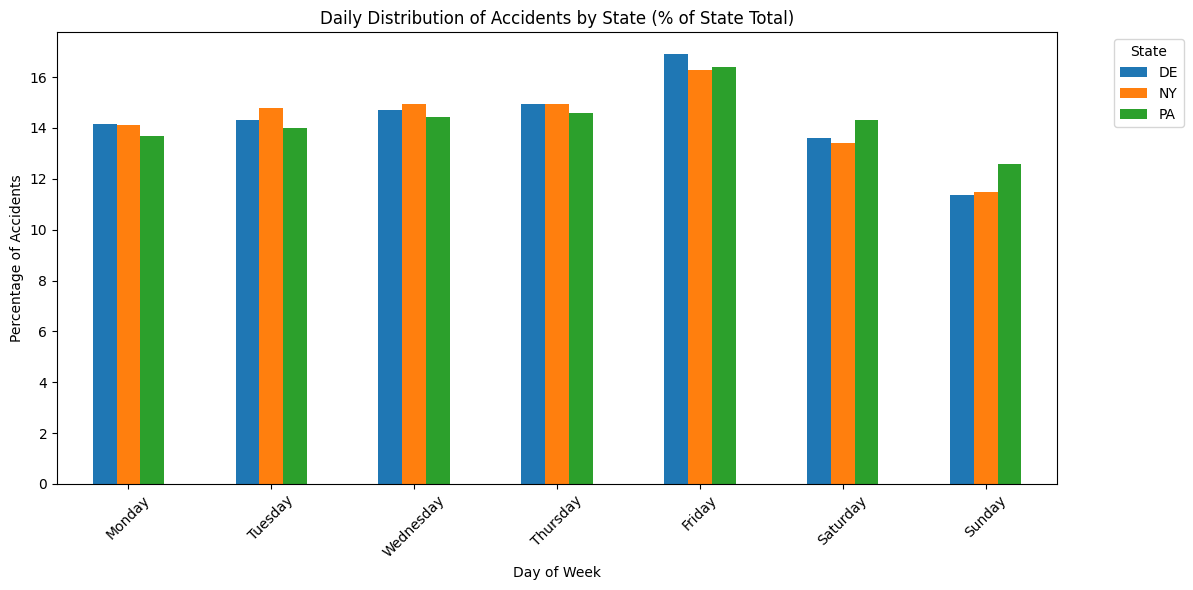

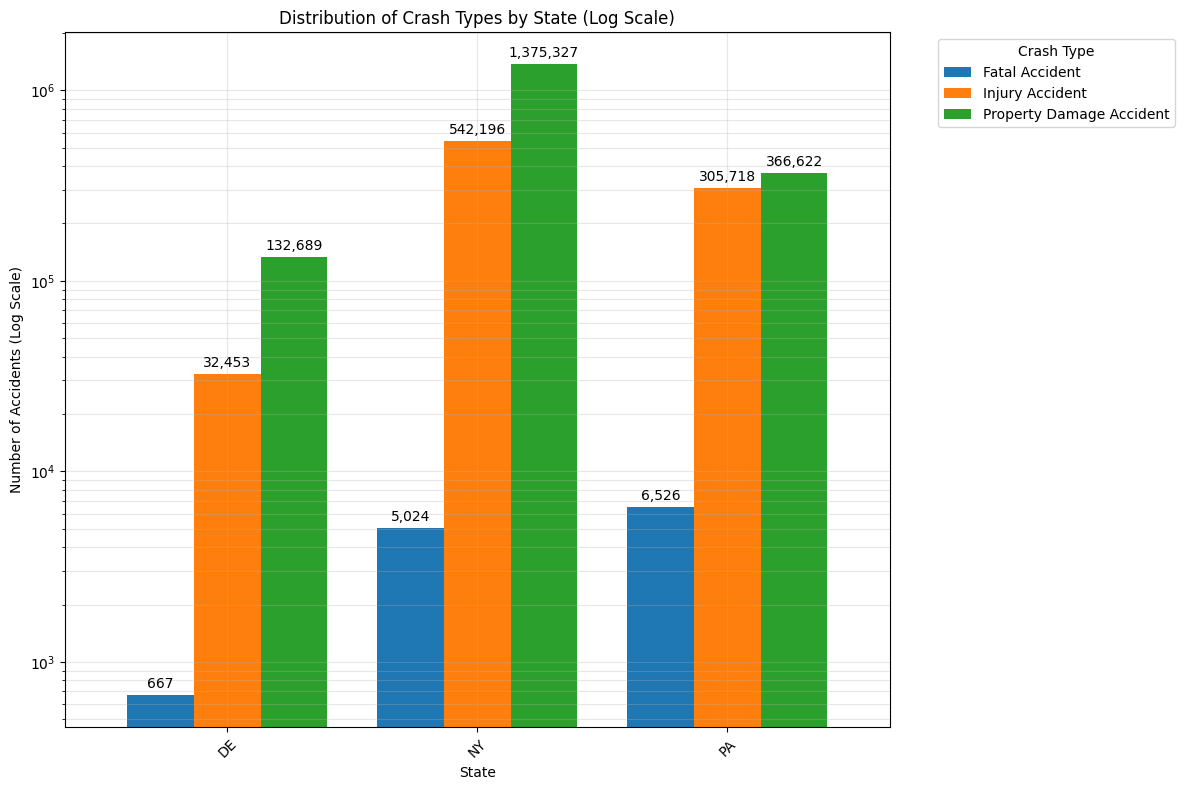

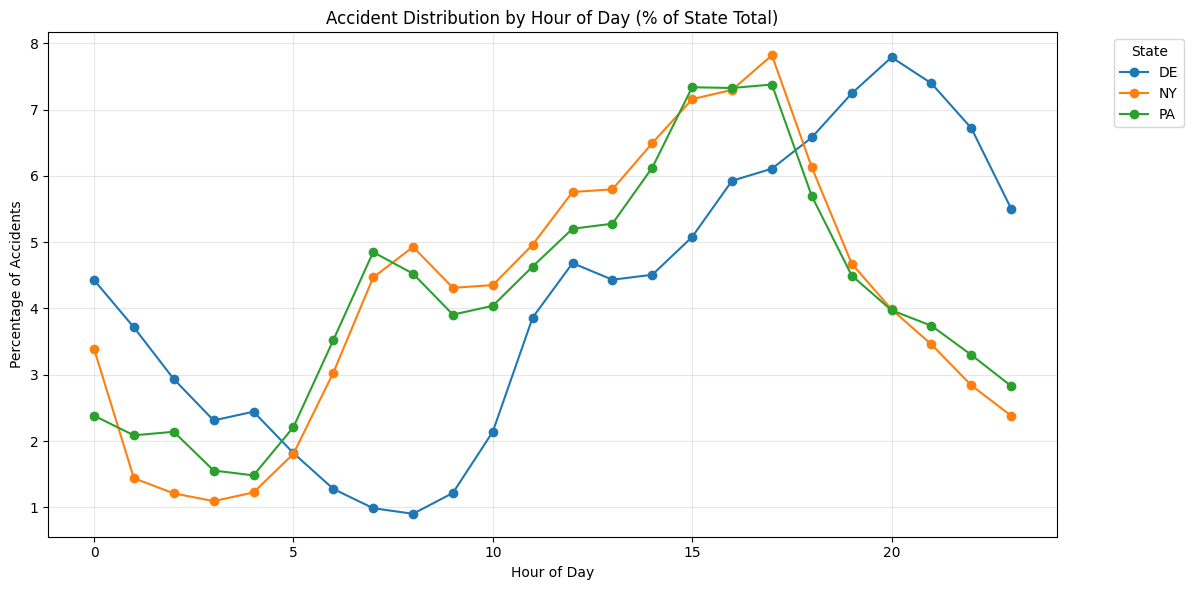

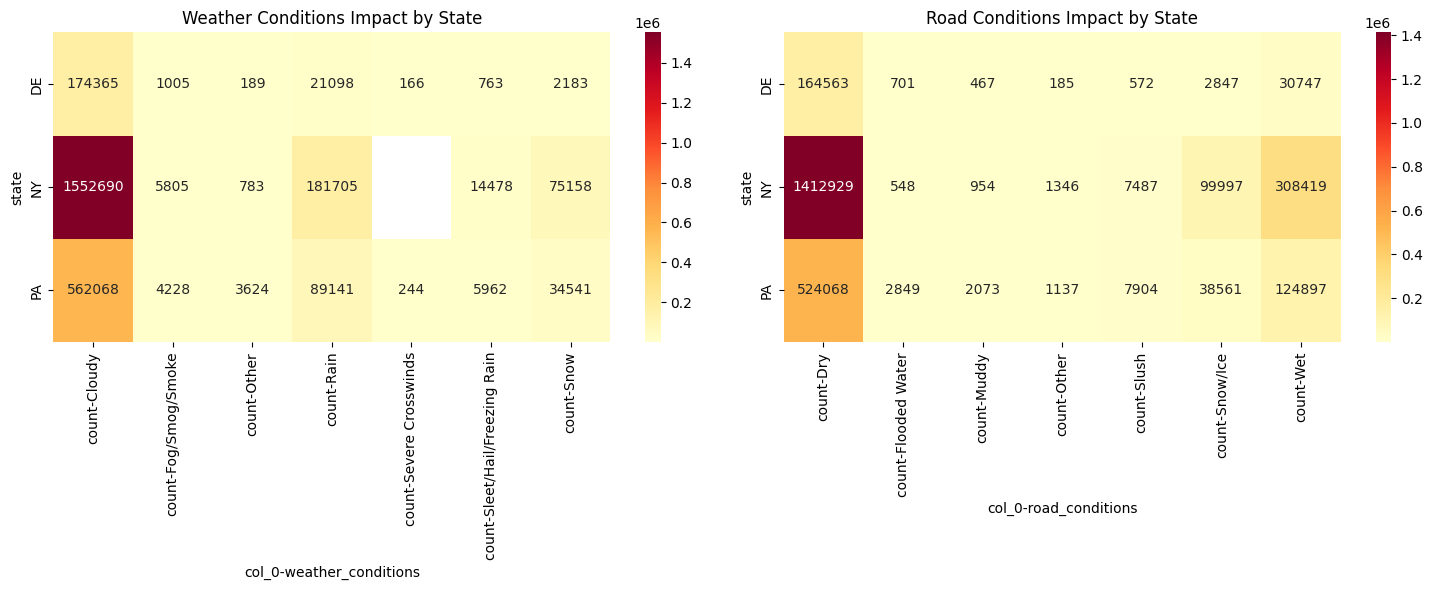

In [ ]:
from typing import List, Optional
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def validate_dataframe(df: pd.DataFrame) -> None:
    required_columns = ['day_of_week', 'state', 'crash_class', 'time',
                       'weather_conditions', 'road_conditions']
    missing_columns = [col for col in required_columns if col not in df.columns]
    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

def plot_daily_distribution(df: pd.DataFrame) -> None:
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
                 'Friday', 'Saturday', 'Sunday']
    day_state_counts = pd.crosstab(df['day_of_week'], df['state'],
                                  normalize='columns') * 100
    day_state_counts = day_state_counts.reindex(day_order)

    fig, ax = plt.subplots(figsize=(12, 6))
    day_state_counts.plot(kind='bar', ax=ax)
    ax.set_title('Daily Distribution of Accidents by State (% of State Total)')
    ax.set_xlabel('Day of Week')
    ax.set_ylabel('Percentage of Accidents')
    ax.legend(title='State', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()

def plot_crash_types(df: pd.DataFrame) -> None:
    crash_type_counts = pd.crosstab(index=df['state'],
                                   columns=df['crash_class']).astype(int)

    fig, ax = plt.subplots(figsize=(12, 8))
    bars = crash_type_counts.plot(kind='bar', ax=ax, width=0.8)

    ax.set_yscale('log')

    for container in ax.containers:
        ax.bar_label(container, padding=3, rotation=0,
                    fmt=lambda x: f'{int(x):,}')

    ax.set_title('Distribution of Crash Types by State (Log Scale)')
    ax.set_xlabel('State')
    ax.set_ylabel('Number of Accidents (Log Scale)')
    ax.legend(title='Crash Type', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.tick_params(axis='x', rotation=45)

    plt.tight_layout()

    ax.grid(True, alpha=0.3, which='both')


def plot_time_distribution(df: pd.DataFrame) -> None:
    df = df.copy()
    df['hour'] = df['time'].apply(lambda x: x.hour if pd.notnull(x) else None)
    hour_state_counts = df.groupby(['hour', 'state']).size().unstack()
    hour_state_counts = hour_state_counts.div(hour_state_counts.sum()) * 100

    fig, ax = plt.subplots(figsize=(12, 6))
    hour_state_counts.plot(kind='line', marker='o', ax=ax)
    ax.set_title('Accident Distribution by Hour of Day (% of State Total)')
    ax.set_xlabel('Hour of Day')
    ax.set_ylabel('Percentage of Accidents')
    ax.legend(title='State', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

def plot_conditions(df: pd.DataFrame) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    weather_counts = pd.crosstab([df['state'], df['weather_conditions']],
                                columns='count').unstack()
    sns.heatmap(weather_counts, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax1)
    ax1.set_title('Weather Conditions Impact by State')

    road_counts = pd.crosstab([df['state'], df['road_conditions']],
                             columns='count').unstack()
    sns.heatmap(road_counts, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax2)
    ax2.set_title('Road Conditions Impact by State')

    plt.tight_layout()

def generate_accident_visualizations(df: pd.DataFrame) -> None:
    try:
        validate_dataframe(df)

        plot_daily_distribution(df)
        plot_crash_types(df)
        plot_time_distribution(df)
        plot_conditions(df)

    except Exception as e:
        print(f"Error generating visualizations: {str(e)}")
        raise

if __name__ == "__main__":
    try:
        generate_accident_visualizations(all_data)
    except Exception as e:
        print(f"Error: {str(e)}")

## Data Distribution
The data is organized into three categories for ease of access and analysis. We are outputting the dataset into Excel (.csv) format for easy accessibility​ and uploading it to Kaggle as a Public Dataset.
The Zip file contains all datasets:
- Full Dataset: Use for large-scale or cross-state analysis.​
- Subsets: Focus on individual states for localized insights.​
- Sample Dataset: Test and explore data quickly with minimal resources.​


In [ ]:
import os


# Create directories for organizing datasets
os.makedirs("Traffic_Accident/Full_Dataset", exist_ok=True)
os.makedirs("Traffic_Accident/Subsets", exist_ok=True)
os.makedirs("Traffic_Accident/Samples", exist_ok=True)


#saving the combined the dataset
all_data.to_csv("Traffic_Accident/Full_Dataset/combined_dataset.csv", index=False)


#Saving the files by states
all_data[all_data['state'] == 'PA'].to_csv("Traffic_Accident/Subsets/PA.csv", index=False)
all_data[all_data['state'] == 'NY'].to_csv("Traffic_Accident/Subsets/NY.csv", index=False)
all_data[all_data['state'] == 'DE'].to_csv("Traffic_Accident/Subsets/DE.csv", index=False)


#Creating a sample data for exploring the datasets directly
sample_data = all_data.sample(50)
sample_data.to_csv("Traffic_Accident/Samples/sample.csv", index=False)


#Compress it into a zip file
!zip -r Traffic_Accident.zip Traffic_Accident


  adding: Traffic_Accident/ (stored 0%)
  adding: Traffic_Accident/Samples/ (stored 0%)
  adding: Traffic_Accident/Samples/sample.csv (deflated 79%)
  adding: Traffic_Accident/Full_Dataset/ (stored 0%)
  adding: Traffic_Accident/Full_Dataset/combined_dataset.csv (deflated 93%)
  adding: Traffic_Accident/Subsets/ (stored 0%)
  adding: Traffic_Accident/Subsets/NY.csv (deflated 93%)
  adding: Traffic_Accident/Subsets/PA.csv (deflated 93%)
  adding: Traffic_Accident/Subsets/DE.csv (deflated 94%)


In [ ]:
from google.colab import files
# Download the ZIP file
files.download("Traffic_Accident.zip")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>